### Introducción a los biopotenciales y adquisición de señales ECG y EMG

##### Presentado por: Alma Olea Barbosa - Lauren Cordero Ramos 

##### Semestre: 2026-2                                     Laboratorio Bioseñales

1- Esquema de las etapas de registros de biopotenciales - Descripción de los componentes de los equipos de adquisición

In [16]:
from PIL import Image

img = Image.open(r"C:\Users\corde\OneDrive\Imágenes\Escritorio\Bioseñales\Biosenales-LaurenCordero-AlmaOlea\Practica 4\Colorful20820Brainstrom281%29.png")
img.show()

Componentes del equipo de adquisición: 

- *Electrodos y cables*: Captan las diferencias de potencial del cuerpo y conducen la señal hacia el circuito. En esta práctica se utilizan para los registros ECG y EMG.

- *Etapa de entrada y amplificador diferencial*: Recibe las señales de los electrodos, amplifica su diferencia y ayuda a reducir las interferencias de modo común. Una alta impedancia de entrada permite no cargar excesivamente la señal biológica.

- *Circuito de acondicionamiento*: Incluye filtros analógicos y otras etapas que ajustan la señal antes de la conversión digital. Los filtros utilizados dependen del tipo de biopotencial y del objetivo de la medición.

- *Convertidor analógico-digital (ADC)*: Convierte la señal analógica en datos digitales. En el montaje descrito por la guía, esta función la realiza el ADC integrado en el microcontrolador de la placa Arduino UNO.

- *Microcontrolador, computador y software*: El microcontrolador gestiona la lectura y transmisión de los datos. El computador y el software permiten visualizar, guardar y procesar las señales adquiridas.

- *Fuente de alimentación*: Proporciona la energía eléctrica necesaria para el funcionamiento de los circuitos. En equipos conectados a una persona, el diseño de alimentación y aislamiento debe cumplir los requisitos de seguridad eléctrica aplicables.

2- Principales fuentes de ruido en el registro de biopotenciales - Análisis


| Fuente | Origen | Naturaleza | Control / eliminación |
|---|---|---|---|
| Red eléctrica (60 Hz) | Acoplamiento capacitivo/inductivo | **Estática** | CMRR alto, DRL, blindaje, cables trenzados, batería, notch |
| Offset DC (semicelda) | Reacción electroquímica del electrodo | **Estática** | Ag/AgCl, mismo lote, pasa-altos |
| Ruido térmico y electrónico | Resistencias y amplificador | **Estática** | Bajo ruido, limitar ancho de banda, promediado |
| Cuantización y aliasing | Resolución del ADC (10 bits) | **Estática** | Antialiasing, fs adecuada, ajustar ganancia |
| Artefacto de movimiento | Deformación de piel y cables | **Variante** | Buena fijación, gel, electrodos activos, pasa-altos |
| Impedancia piel-electrodo | Sudor, gel seco, grasa | **Variante** | Limpieza, abrasión, gel, alta impedancia de entrada |
| Deriva de línea base | Respiración, movimiento | **Variante** | Pasa-altos (~0.5 Hz ECG), detrending |
| Ruido muscular en ECG | Músculos vecinos (20–500 Hz) | **Variante** | Relajación, pasa-bajos, promediado |
| Crosstalk entre bioseñales | ECG en sEMG, músculos vecinos | **Variante** | Ubicación correcta, pasa-altos (~20 Hz), ICA |
| Interferencia EM / RF | Celulares, electrobisturí, fuentes conmutadas | **Variante** | Blindaje, filtros RFI, alejar fuentes |



3-  Acoplamiento piel-electrodo - Análisis

- _Problemática_. La piel, en particular su capa córnea (células muertas y secas), tiene una impedancia muy alta, de decenas a cientos de kΩ si no se prepara. A esto se suman el potencial de semicelda del electrodo, que genera un offset DC, y la doble capa electroquímica, cuya impedancia depende de la frecuencia. Si las impedancias de los electrodos no son iguales, el ruido de modo común (60 Hz) se convierte en ruido diferencial. Además, la interfaz cambia con el sudor, el secado del gel y el movimiento, lo que produce deriva de línea base y artefactos.

- _Estrategias_. Se limpia, rasura y abrade suavemente la piel, y se usa gel electrolítico y electrodos de Ag/AgCl, que son estables y no polarizables. Se fijan bien los electrodos y los cables para reducir el movimiento. También se emplean electrodos activos, amplificadores con alta impedancia de entrada y CMRR alto, y un circuito de pierna derecha (DRL). Antes de registrar se verifica que la impedancia sea baja (idealmente menor a 5-10 kΩ) y similar entre electrodos.

- _¿Por qué es la etapa más crítica?_ Es el primer eslabón de la cadena, por lo que cualquier error se propaga a las etapas siguientes y no se puede corregir después. Las señales son muy pequeñas (ECG ≈ 1 mV, sEMG 50 µV-5 mV, EEG 10-100 µV), así que el offset y los artefactos de esta interfaz son comparables o mayores que la señal útil. Es además la fuente dominante de ruido y es variable e impredecible. El filtrado posterior no puede eliminarlo del todo, porque se superpone en frecuencia con la señal y puede distorsionarla. Por eso una buena interfaz reduce el ruido desde el origen.

4- Análisis de la variabilidad de la frecuencia cardiaca

4.1- Picos R con Neurokit y Detectors

In [17]:
%pip install "numpy<2" "nolds==0.6.2" "astropy<6.0" hrv-analysis neurokit2 py-ecg-detectors matplotlib pandas scipy scikit-learn PyWavelets

In [18]:
from hrvanalysis import get_time_domain_features

In [19]:
import numpy as np, pandas as pd, neurokit2 as nk
import matplotlib.pyplot as plt
from ecgdetectors import Detectors

ruta = r"C:\Users\corde\OneDrive\Imágenes\Escritorio\Bioseñales\Biosenales-LaurenCordero-AlmaOlea\Practica 4\SerialBiosenales EKG.txt"
datos = np.loadtxt(ruta)

if datos.ndim == 2:              # 2 columnas: tiempo y señal
    t, ecg = datos[:, 0], datos[:, 1]
    fs = 1 / np.median(np.diff(t))
else:                            # 1 columna: solo la señal
    ecg = datos
    fs = 100                     # delay(10) en el Arduino -> ~100 Hz

ecg = ecg - np.mean(ecg)
print(f"Muestras: {len(ecg)} | fs = {fs:.1f} Hz | duración = {len(ecg)/fs:.1f} s")

Muestras: 1000 | fs = 100.0 Hz | duración = 10.0 s


In [20]:
ecg_clean = nk.ecg_clean(ecg, sampling_rate=fs, method="neurokit")
picos = {}

# NeuroKit
for m in ["neurokit", "pantompkins1985", "hamilton2002", "christov2004", "engzeemod2012"]:
    try:
        _, info = nk.ecg_peaks(ecg_clean, sampling_rate=fs, method=m)
        picos[f"NK-{m}"] = np.array(info["ECG_R_Peaks"])
    except Exception as e:
        print(f"NK-{m}: omitido ({type(e).__name__}: {e})")

# Detectors (usan la señal cruda)
det = Detectors(fs)
for nombre, f in {"DET-pan_tompkins": det.pan_tompkins_detector,
                  "DET-hamilton": det.hamilton_detector,
                  "DET-christov": det.christov_detector,
                  "DET-engzee": det.engzee_detector,
                  "DET-two_average": det.two_average_detector,
                  "DET-swt": det.swt_detector}.items():
    try:
        picos[nombre] = np.array(f(ecg))
    except Exception as e:
        print(f"{nombre}: omitido, no soporta fs = {fs:.0f} Hz ({type(e).__name__})")

# Alinear todos los picos al máximo local (algunos detectores marcan con desfase)
def refinar(p, sig, ventana):
    out = []
    for i in p:
        a, b = max(0, i-ventana), min(len(sig), i+ventana+1)
        out.append(a + int(np.argmax(sig[a:b])))
    return np.unique(out)

ecg_ref = nk.signal_filter(ecg, sampling_rate=fs, lowcut=5, highcut=20, method="butterworth", order=2)
picos = {k: refinar(v, ecg_ref, int(0.10*fs)) for k, v in picos.items()}

DET-engzee: omitido, no soporta fs = 100 Hz (ValueError)


In [21]:
filas = []
for nombre, p in picos.items():
    if len(p) < 2:
        filas.append({"Algoritmo": nombre, "N picos": len(p), "FC media (lpm)": None,
                      "RR mín (s)": None, "RR máx (s)": None})
        continue
    rr = np.diff(p) / fs
    filas.append({"Algoritmo": nombre, "N picos": len(p),
                  "FC media (lpm)": round(60 / rr.mean(), 1),
                  "RR mín (s)": round(rr.min(), 2),
                  "RR máx (s)": round(rr.max(), 2)})
display(pd.DataFrame(filas))

,Algoritmo,N picos,FC media (lpm),RR mín (s),RR máx (s)
0,NK-neurokit,13,81.4,0.65,0.85
1,NK-pantompkins1985,14,84.1,0.43,0.85
2,NK-hamilton2002,14,84.1,0.43,0.85
3,NK-christov2004,14,84.1,0.43,0.85
4,NK-engzeemod2012,12,74.7,0.65,1.37
5,DET-pan_tompkins,14,85.3,0.31,0.86
6,DET-hamilton,14,84.1,0.43,0.85
7,DET-christov,14,84.1,0.43,0.85
8,DET-two_average,13,81.4,0.65,0.85
9,DET-swt,15,90.6,0.29,0.85


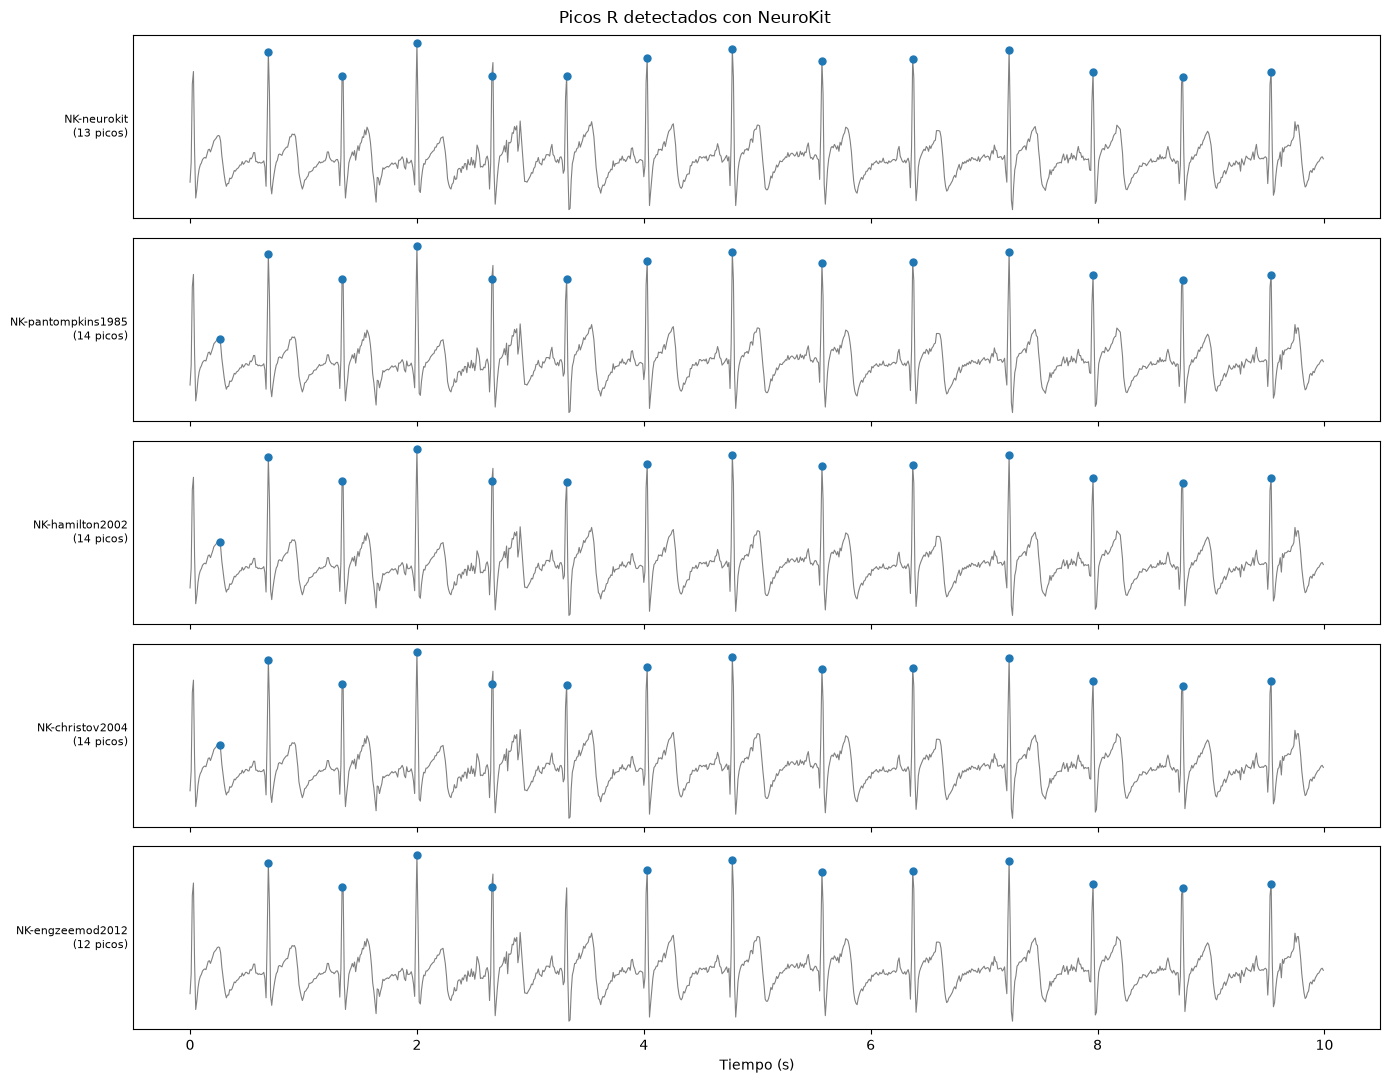

In [22]:

# Corregir el error de fuentes de Matplotlib en Windows/Anaconda
try:
    matplotlib.rcParams['font.enable_last_resort'] = False
except KeyError:
    pass
plt.rcParams['font.sans-serif'] = ['DejaVu Sans', 'Arial']
plt.rcParams['font.family'] = 'sans-serif'

# Preparación de tiempo y agrupación de picos
t = np.arange(len(ecg)) / fs
nk_picos  = {k: v for k, v in picos.items() if k.startswith("NK-")}
det_picos = {k: v for k, v in picos.items() if k.startswith("DET-")}

def graficar(grupo, titulo, color):
    # Validación por si el grupo no contiene datos
    if not grupo:
        print(f"No hay picos para graficar en: {titulo}")
        return
    
    fig, axs = plt.subplots(len(grupo), 1, figsize=(14, 2.2 * len(grupo)), sharex=True)
    axs_list = np.atleast_1d(axs)
    
    for ax, (nombre, p) in zip(axs_list, grupo.items()):
        ax.plot(t, ecg, color="gray", lw=0.8)
        if len(p) > 0:
            ax.plot(t[p], ecg[p], "o", color=color, ms=5)
        ax.set_ylabel(f"{nombre}\n({len(p)} picos)", rotation=0, ha="right", va="center", fontsize=8)
        ax.set_yticks([])
        
    axs_list[-1].set_xlabel("Tiempo (s)")
    fig.suptitle(titulo)
    plt.tight_layout()
    plt.show()

# Llamada a la función
graficar(nk_picos, "Picos R detectados con NeuroKit", "tab:blue")

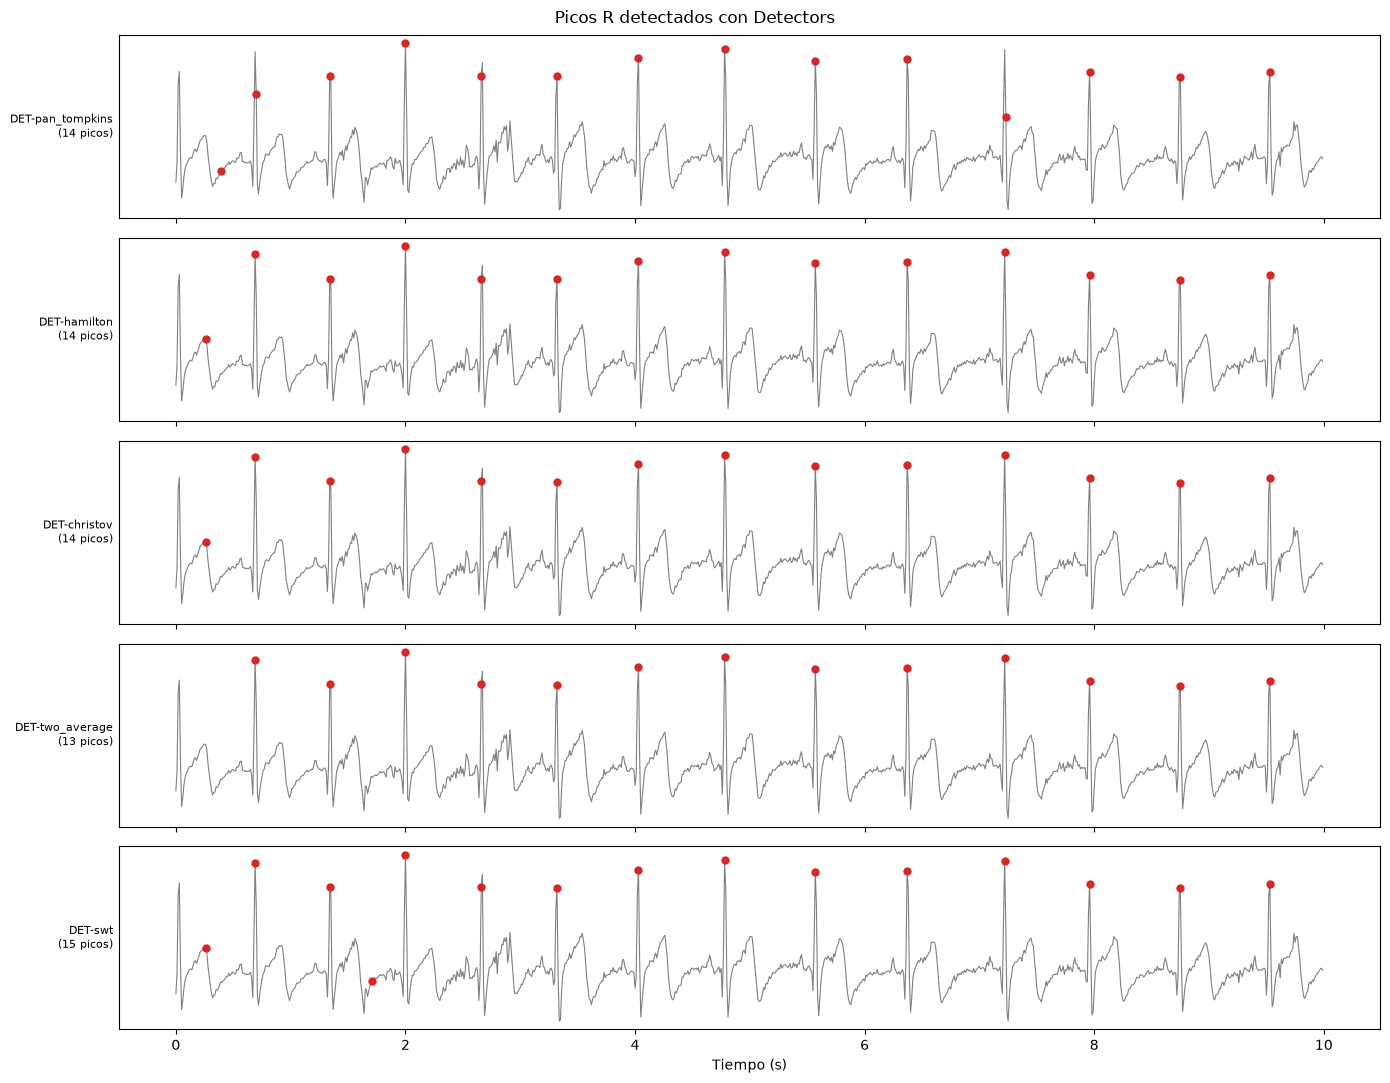

In [23]:
# Gráficas de picos R: Detectors
graficar(det_picos, "Picos R detectados con Detectors", "tab:red")

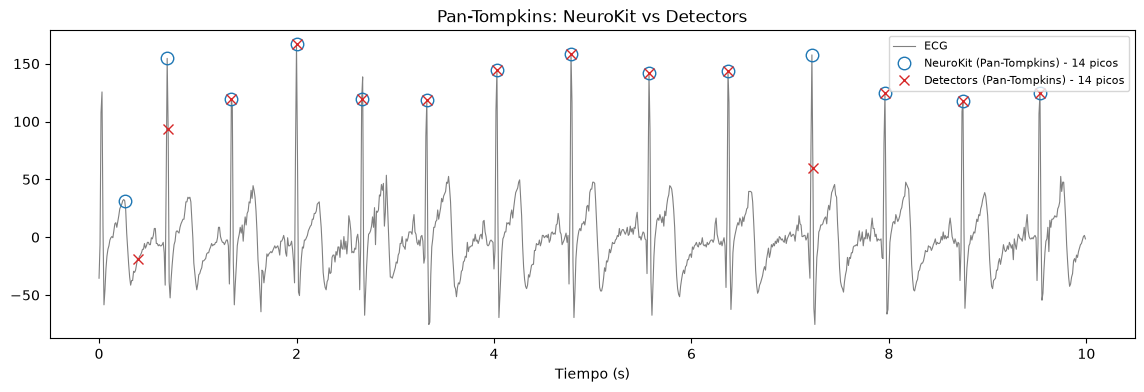

In [24]:
# Comparación directa: el mismo algoritmo (Pan-Tompkins) en ambas librerías
plt.figure(figsize=(14, 4))
plt.plot(t, ecg, color="gray", lw=0.8, label="ECG")
p1, p2 = picos["NK-pantompkins1985"], picos["DET-pan_tompkins"]   # requiere que ambos existan
plt.plot(t[p1], ecg[p1], "o", color="tab:blue", ms=9, mfc="none", label=f"NeuroKit (Pan-Tompkins) - {len(p1)} picos")
plt.plot(t[p2], ecg[p2], "x", color="tab:red", ms=7, label=f"Detectors (Pan-Tompkins) - {len(p2)} picos")
plt.xlabel("Tiempo (s)"); plt.legend(loc="upper right", fontsize=8)
plt.title("Pan-Tompkins: NeuroKit vs Detectors")
plt.show()

4.2- Cálculo del HRV

RESULTADOS DEL ANÁLISIS HRV
Número de picos R: 14
Número de intervalos RR: 13
Frecuencia cardíaca media: 84.14 lpm
Intervalo RR medio: 713.08 ms
SDNN: 106.96 ms
RMSSD: 77.19 ms
pNN50: 16.67 %


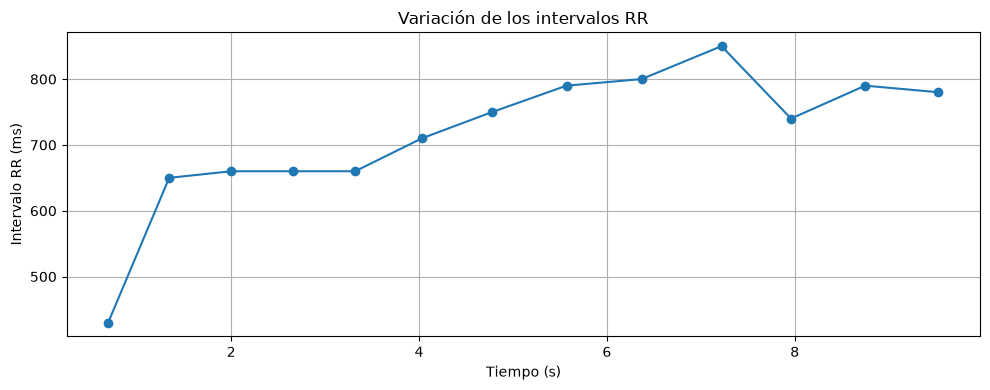

In [25]:
# 4.2. Cálculo de la variabilidad de la frecuencia cardíaca (HRV)

# Seleccionar los picos R detectados con Hamilton en NeuroKit
picos_hrv = picos["NK-hamilton2002"]

# Calcular los intervalos RR en segundos y milisegundos
rr_s = np.diff(picos_hrv) / fs
rr_ms = rr_s * 1000

if len(rr_s) < 2:
    print("No hay suficientes intervalos RR para calcular las métricas.")
else:
    # Métricas básicas de HRV
    fc_media = 60 / np.mean(rr_s)
    rr_medio = np.mean(rr_ms)
    sdnn = np.std(rr_ms, ddof=1)
    rmssd = np.sqrt(np.mean(np.diff(rr_ms) ** 2))
    pnn50 = 100 * np.sum(np.abs(np.diff(rr_ms)) > 50) / len(np.diff(rr_ms))

    print("RESULTADOS DEL ANÁLISIS HRV")
    print(f"Número de picos R: {len(picos_hrv)}")
    print(f"Número de intervalos RR: {len(rr_s)}")
    print(f"Frecuencia cardíaca media: {fc_media:.2f} lpm")
    print(f"Intervalo RR medio: {rr_medio:.2f} ms")
    print(f"SDNN: {sdnn:.2f} ms")
    print(f"RMSSD: {rmssd:.2f} ms")
    print(f"pNN50: {pnn50:.2f} %")

    # Gráfica de los intervalos RR
    tiempo_rr = picos_hrv[1:] / fs
    plt.figure(figsize=(10, 4))
    plt.plot(tiempo_rr, rr_ms, marker="o")
    plt.xlabel("Tiempo (s)")
    plt.ylabel("Intervalo RR (ms)")
    plt.title("Variación de los intervalos RR")
    plt.grid(True)
    plt.tight_layout()
    plt.show()


La variabilidad de la frecuencia cardíaca (HRV) describe las variaciones en el tiempo entre latidos consecutivos, estimadas a partir de los intervalos RR. Para este análisis se utilizaron los picos R detectados mediante el algoritmo Hamilton de NeuroKit. A partir de ellos se calcularon la frecuencia cardíaca media, el intervalo RR medio y tres índices del dominio del tiempo: SDNN, RMSSD y pNN50.

El SDNN representa la desviación estándar de los intervalos RR y permite cuantificar su dispersión. El RMSSD corresponde a la raíz cuadrada de la media de las diferencias sucesivas al cuadrado entre intervalos RR, mientras que el pNN50 expresa el porcentaje de diferencias sucesivas superiores a 50 ms. Estos indicadores describen distintos aspectos de la variación de los intervalos entre latidos.

Los valores obtenidos deben interpretarse teniendo en cuenta la duración y la calidad del registro. En esta práctica se analizaron aproximadamente 10 segundos de señal, por lo que los índices calculados son exploratorios y no permiten establecer conclusiones clínicas sobre la HRV. Para una caracterización más fiable se necesita un registro de mayor duración, detección y revisión de artefactos, y una selección adecuada de intervalos normales.

4.3- Implementación de función de hryanalysis

In [26]:
nn_intervals = rr_ms.tolist()

if len(nn_intervals) >= 2:
    caracteristicas_hrv = get_time_domain_features(nn_intervals)

    print("CARACTERÍSTICAS HRV EN EL DOMINIO DEL TIEMPO")
    for caracteristica, valor in caracteristicas_hrv.items():
        if isinstance(valor, (int, float, np.integer, np.floating)):
            print(f"{caracteristica}: {valor:.4f}")
        else:
            print(f"{caracteristica}: {valor}")
else:
    print("No hay suficientes intervalos para calcular las características HRV.")


CARACTERÍSTICAS HRV EN EL DOMINIO DEL TIEMPO
mean_nni: 713.0769
sdnn: 106.9567
sdsd: 71.4677
nni_50: 2.0000
pnni_50: 16.6667
nni_20: 7.0000
pnni_20: 58.3333
rmssd: 77.1902
median_nni: 740.0000
range_nni: 420.0000
cvsd: 0.1082
cvnni: 0.1500
mean_hr: 86.5052
max_hr: 139.5349
min_hr: 70.5882
std_hr: 16.8252


In [27]:
# Convertir los intervalos RR a una lista en milisegundos
nn_intervals = rr_ms.tolist()

# Calcular las características de HRV en el dominio del tiempo
caracteristicas_hrv = get_time_domain_features(nn_intervals)

# Mostrar los resultados
print("Características de HRV en el dominio del tiempo:")
print(caracteristicas_hrv)


Características de HRV en el dominio del tiempo:
{'mean_nni': 713.0769230769231, 'sdnn': 106.95673700026374, 'sdsd': 71.46774719332413, 'nni_50': 2, 'pnni_50': 16.666666666666668, 'nni_20': 7, 'pnni_20': 58.333333333333336, 'rmssd': 77.19024117939607, 'median_nni': 740.0, 'range_nni': 420.0, 'cvsd': 0.10824952916204411, 'cvnni': 0.14999326655916168, 'mean_hr': 86.50523219114672, 'max_hr': 139.53488372093022, 'min_hr': 70.58823529411765, 'std_hr': 16.825159863108933}


El cálculo de las características de la variabilidad de la frecuencia cardíaca (HRV) permite analizar las variaciones en los intervalos de tiempo entre los picos R consecutivos del ECG. Estas características, como el RMSSD y el SDNN, aportan información sobre la variabilidad de los intervalos cardíacos. Sin embargo, debido a que el fragmento de señal analizado es corto, los resultados deben interpretarse con precaución y no permiten establecer conclusiones clínicas definitivas.

5- Aplicaciones clínicas del ECG y EMG

##### 5.1. Aplicaciones clínicas del electrocardiograma (ECG)

| Aplicación clínica | Tipo de registro | Procesamiento de la señal |
|---|---|---|
| 1. Detección de arritmias cardíacas | ECG de superficie, generalmente de 12 derivaciones para evaluación clínica; también pueden utilizarse registros ambulatorios prolongados. | Filtrado de ruido, detección de ondas P y complejos QRS, cálculo de intervalos RR y análisis de la regularidad del ritmo. En registros prolongados se pueden emplear algoritmos de detección de episodios arrítmicos. |
| 2. Evaluación de isquemia e infarto de miocardio | ECG de 12 derivaciones, realizado en reposo y, según la indicación clínica, con registros seriados. | Corrección de la línea base, filtrado controlado y análisis de la morfología del complejo QRS, el segmento ST y la onda T. La interpretación debe realizarse junto con la información clínica y otras pruebas diagnósticas. |
| 3. Evaluación de la variabilidad de la frecuencia cardíaca | Registro ECG continuo con duración adecuada para el objetivo del estudio; para muchos análisis de corto plazo se utilizan registros de aproximadamente cinco minutos bajo condiciones controladas. | Detección de picos R, cálculo de intervalos NN, revisión de artefactos y extracción de índices como SDNN, RMSSD y pNN50. También pueden analizarse componentes frecuenciales cuando el protocolo lo requiere. |

##### 5.2. Aplicaciones clínicas de la electromiografía (EMG)

| Aplicación clínica | Tipo de registro | Procesamiento de la señal |
|---|---|---|
| 1. Evaluación de enfermedades neuromusculares | Electromiografía con electrodo de aguja y, según el caso, estudios complementarios de conducción nerviosa. | Amplificación y filtrado de la señal, análisis de potenciales de unidad motora y evaluación de su amplitud, duración y patrón de reclutamiento. La interpretación corresponde a personal clínico especializado. |
| 2. Evaluación de la activación muscular y la fatiga | Electromiografía de superficie (sEMG), con electrodos ubicados sobre el músculo durante contracciones controladas. | Eliminación de artefactos, filtrado pasa-banda, rectificación y cálculo de la amplitud mediante RMS. También puede estudiarse el cambio de la frecuencia mediana del espectro durante contracciones sostenidas, teniendo en cuenta las condiciones del registro. |
| 3. Control de prótesis mioeléctricas y dispositivos de asistencia | Registro sEMG mediante electrodos superficiales ubicados sobre músculos residuales u otros músculos seleccionados. | Filtrado, segmentación en ventanas, extracción de características como RMS y longitud de onda, y clasificación de patrones musculares para generar comandos de control. El sistema debe validarse considerando la variabilidad de la señal y los artefactos. |

##### Análisis general de las aplicaciones

El ECG permite estudiar la actividad eléctrica cardíaca y obtener información sobre el ritmo, la conducción y determinados cambios asociados con enfermedades cardiovasculares. La EMG, por su parte, permite estudiar la actividad eléctrica muscular, tanto para apoyar la evaluación neuromuscular como para analizar la función muscular y desarrollar sistemas de asistencia.

En ambos casos, la utilidad de la señal depende de la calidad del registro, la ubicación de los electrodos, el control de las interferencias y la selección de métodos de procesamiento apropiados. El procesamiento digital facilita la identificación de características relevantes, pero no sustituye la valoración clínica ni permite establecer un diagnóstico de manera aislada.

#### 6- Conclusiones

- La calidad de un registro de biopotenciales depende de toda la cadena de adquisición (electrodos, amplificador diferencial, acondicionamiento, ADC y software), porque cada etapa puede añadir ruido o limitar la información. En esta práctica, el ADC de 10 bits del Arduino UNO limita la resolución, por lo que hay que ajustar la ganancia y la frecuencia de muestreo a la señal.

- Las fuentes de ruido se pueden separar según su comportamiento en el tiempo. Las estáticas (red de 60 Hz, offset DC, ruido térmico y cuantización) se controlan sobre todo con el diseño del hardware y con filtrado. Las variantes (movimiento, impedancia, deriva, ruido muscular y crosstalk) dependen de la técnica del operador y del sujeto, y por eso son más difíciles de eliminar.

- El acoplamiento piel-electrodo es la etapa más crítica porque es el primer eslabón de la cadena y la fuente dominante de ruido, mientras que las señales son de microvoltios a milivoltios. Una buena preparación de la piel, electrodos de Ag/AgCl y una fijación correcta reducen el ruido en el origen, algo que el filtrado posterior no logra del todo.

- El análisis de la variabilidad de la frecuencia cardíaca permitió comprender la importancia de identificar correctamente los picos R y calcular los intervalos entre ellos para obtener características temporales de la señal ECG. Asimismo, se evidenció que la calidad de la detección de los picos y la duración del registro influyen en la interpretación de los resultados, por lo que es necesario contar con señales de mayor duración para realizar un análisis de HRV más confiable.

### 7- Referencias bibliográficas

- Kligfield P, Gettes LS, Bailey JJ, et al. Recommendations for the standardization and interpretation of the electrocardiogram. Part I: The electrocardiogram and its technology. Circulation. 2007;115(10):1306-1324. 

- Huigen E, Peper A, Grimbergen CA. Investigation into the origin of the noise of surface electrodes. Med Biol Eng Comput. 2002;40(3):332-338. 

- Chi YM, Jung TP, Cauwenberghs G. Dry-contact and noncontact biopotential electrodes: methodological review. IEEE Rev Biomed Eng. 2010;3:106-119.

- Merletti R, Muceli S. Tutorial. Surface EMG detection in space and time: best practices. J Electromyogr Kinesiol. 2019;49:102363. 

- Searle A, Kirkup L. A direct comparison of wet, dry and insulating bioelectric recording electrodes. Physiol Meas. 2000;21(2):271-283.